In [4]:
import scanpy as sc
import pandas as pd
import os
import sys
import numpy as np
import gzip
import matplotlib.pyplot as pl
import re
import seaborn as sns
from scipy.io import mmread
from scipy.sparse import csr_matrix
import tqdm.notebook as tq
import shutil
import sys 
sys.path.insert(0, '../')
import utils
from importlib import reload
reload(utils)
from utils import *

# This is a Directory including raw counts downloaded from the GEO repo.  
data_path = 'E:\\VSCODE\\PrePR-CT\\Dataset\\'

# Output Results Directory 
save_path_results = "E:\\VSCODE\\PrePR-CT\\Results\\"

# Input Data Directory 
save_path_data = "E:\\VSCODE\\PrePR-CT\\Data\\"


In [5]:
# Define the file path for the gene annotation file
var = data_path+'GSE96583_batch2.genes.tsv.gz'

# Read the tab-separated file into a DataFrame, no header, using the first column as index
var = pd.read_csv(var, sep='\t', header=None, index_col=0)

# Reset the index so that the original index becomes a column again
var.reset_index(inplace =True)

# Rename the columns for clarity: column 0 → 'ensemble_id', column 1 → 'gene_name'
var = var.rename(columns={0: 'ensemble_id', 1: 'gene_name'})

# Set 'gene_name' as the new index of the DataFrame
var.set_index('gene_name', inplace = True)

# Display the resulting DataFrame
var

,ensemble_id
gene_name,
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945
...,...
MT-ND4L,ENSG00000212907
MT-ND4,ENSG00000198886
MT-ND5,ENSG00000198786


In [7]:
# Define the file path for the t-SNE data file (cell-level metadata/coordinates)
obs = data_path+'GSE96583_batch2.total.tsne.df.tsv.gz'

# Read the tab-separated file into a DataFrame
obs = pd.read_csv(obs, sep='\t')

# Display the resulting DataFrame
obs

,tsne1,tsne2,ind,stim,cluster,cell,multiplets
AAACATACAATGCC-1,-4.277833,-19.294709,107,ctrl,5,CD4 T cells,doublet
AAACATACATTTCC-1,-27.640373,14.966629,1016,ctrl,9,CD14+ Monocytes,singlet
AAACATACCAGAAA-1,-27.493646,28.924885,1256,ctrl,9,CD14+ Monocytes,singlet
AAACATACCAGCTA-1,-28.132584,24.925484,1256,ctrl,9,CD14+ Monocytes,doublet
AAACATACCATGCA-1,-10.468194,-5.984389,1488,ctrl,3,CD4 T cells,singlet
...,...,...,...,...,...,...,...
TTTGCATGCTAAGC-1,25.142392,6.603815,107,stim,6,CD4 T cells,singlet
TTTGCATGGGACGA-1,14.359657,10.965601,1488,stim,6,CD4 T cells,singlet
TTTGCATGGTGAGG-1,27.317997,7.933458,1488,stim,6,CD4 T cells,ambs
TTTGCATGGTTTGG-1,13.744084,9.347784,1244,stim,6,CD4 T cells,ambs


In [9]:
# Read the Matrix Market file (.mtx.gz) and convert it to a compressed sparse row (CSR) matrix
counts_mat_1 = csr_matrix(mmread(data_path+'GSM2560248_2.1.mtx.gz'))

# Display the shape (rows = genes, columns = cells) of the sparse count matrix
counts_mat_1.shape

(35635, 14619)

In [10]:
# Read the second Matrix Market file (.mtx.gz) and convert it to a compressed sparse row (CSR) matrix
counts_mat_2 = csr_matrix(mmread(data_path+'GSM2560249_2.2.mtx.gz'))

# Display the shape (rows = genes, columns = cells) of the second sparse count matrix
counts_mat_2.shape

(35635, 14446)

In [11]:
# Define the file path for the first set of cell barcodes
barcodes_1 = data_path+'GSM2560248_barcodes.tsv.gz'

# Read the barcodes file into a DataFrame (no header, tab-separated)
barcodes_1 = pd.read_csv(barcodes_1, sep='\t', header=None)

# Subset the obs DataFrame to only include rows corresponding to these barcodes
obs_barcodes_1 = obs.loc[barcodes_1[0].tolist()]

# Display the subset DataFrame with metadata for the first batch of barcodes
obs_barcodes_1

,tsne1,tsne2,ind,stim,cluster,cell,multiplets
AAACATACAATGCC-1,-4.277833,-19.294709,107,ctrl,5,CD4 T cells,doublet
AAACATACATTTCC-1,-27.640373,14.966629,1016,ctrl,9,CD14+ Monocytes,singlet
AAACATACCAGAAA-1,-27.493646,28.924885,1256,ctrl,9,CD14+ Monocytes,singlet
AAACATACCAGCTA-1,-28.132584,24.925484,1256,ctrl,9,CD14+ Monocytes,doublet
AAACATACCATGCA-1,-10.468194,-5.984389,1488,ctrl,3,CD4 T cells,singlet
...,...,...,...,...,...,...,...
TTTGCATGCTTCGC-1,-30.296922,-7.644350,101,ctrl,4,B cells,singlet
TTTGCATGGCAGTT-1,-31.202417,7.029632,1016,ctrl,9,FCGR3A+ Monocytes,singlet
TTTGCATGGGAACG-1,17.791388,-21.583107,1016,ctrl,10,CD8 T cells,singlet
TTTGCATGGTCCTC-1,-25.741550,-13.367704,1256,ctrl,4,B cells,singlet


In [12]:
# Define the file path for the second set of cell barcodes
barcodes_2 = data_path+'GSM2560249_barcodes.tsv.gz'

# Read the barcodes file into a DataFrame (no header, tab-separated)
barcodes_2 = pd.read_csv(barcodes_2, sep='\t', header=None)

# Subset the obs DataFrame to only include rows corresponding to these barcodes
obs_barcodes_2 = obs.loc[barcodes_2[0].tolist()]

# Display the subset DataFrame with metadata for the second batch of barcodes
obs_barcodes_2


,tsne1,tsne2,ind,stim,cluster,cell,multiplets
AAACATACCAAGCT-1,26.198495,-6.930392,101,stim,10,CD8 T cells,singlet
AAACATACCCCTAC-1,31.002792,21.730184,1488,stim,2,Dendritic cells,singlet
AAACATACCCGTAA-1,3.992437,11.494216,1244,stim,6,CD4 T cells,ambs
AAACATACCCTCGT-1,-15.655645,4.109124,1488,stim,4,B cells,singlet
AAACATACGAGGTG-1,5.987393,3.533825,1488,stim,6,CD4 T cells,singlet
...,...,...,...,...,...,...,...
TTTGCATGCTAAGC-1,25.142392,6.603815,107,stim,6,CD4 T cells,singlet
TTTGCATGGGACGA-1,14.359657,10.965601,1488,stim,6,CD4 T cells,singlet
TTTGCATGGTGAGG-1,27.317997,7.933458,1488,stim,6,CD4 T cells,ambs
TTTGCATGGTTTGG-1,13.744084,9.347784,1244,stim,6,CD4 T cells,ambs


In [13]:
# Initialize an empty list to store AnnData objects
adata_list = []

# Create an AnnData object for the first dataset
# counts_mat_1.T → transpose so that rows = cells, columns = genes
# obs = obs_barcodes_1 → metadata for the corresponding cells
adata_1 = sc.AnnData(counts_mat_1.T, obs=obs_barcodes_1)

# Filter out cells labeled as multiplets (doublets or ambiguous)
adata_1 = adata_1[~adata_1.obs.multiplets.isin(['doublet', 'ambs'])]

# Ensure that gene (var) names are unique
adata_1.var_names_make_unique()

# Ensure that cell (obs) names are unique
adata_1.obs_names_make_unique()

# Append the processed AnnData object to the list
adata_list.append(adata_1)

# Display the AnnData object summary
adata_1

AnnData object with n_obs × n_vars = 12315 × 35635
    obs: 'tsne1', 'tsne2', 'ind', 'stim', 'cluster', 'cell', 'multiplets'

In [14]:
# Create an AnnData object for the second dataset
# counts_mat_2.T → transpose so that rows = cells, columns = genes
# obs = obs_barcodes_2 → metadata for the corresponding cells
adata_2 = sc.AnnData(counts_mat_2.T, obs=obs_barcodes_2)

# Filter out cells labeled as multiplets (doublets or ambiguous)
adata_2 = adata_2[~adata_2.obs.multiplets.isin(['doublet', 'ambs'])]

# Ensure that gene (var) names are unique
adata_2.var_names_make_unique()

# Ensure that cell (obs) names are unique
adata_2.obs_names_make_unique()

# Append the processed AnnData object to the list
adata_list.append(adata_2)

# Display the AnnData object summary
adata_2


AnnData object with n_obs × n_vars = 12285 × 35635
    obs: 'tsne1', 'tsne2', 'ind', 'stim', 'cluster', 'cell', 'multiplets'

In [15]:
# Concatenate the list of AnnData objects along the cell axis (rows)
# join='outer' → keep all genes across datasets (union of features)
adata = sc.concat(adata_list, axis=0, join='outer')

# Assign the gene annotation DataFrame (var) to the AnnData object
adata.var = var

# Ensure that gene (var) names are unique
adata.var_names_make_unique()

# Ensure that cell (obs) names are unique
adata.obs_names_make_unique()

In [16]:
adata

AnnData object with n_obs × n_vars = 24600 × 35635
    obs: 'tsne1', 'tsne2', 'ind', 'stim', 'cluster', 'cell', 'multiplets'
    var: 'ensemble_id'

In [17]:
adata.obs.stim.value_counts()

stim
ctrl    12549
stim    12051
Name: count, dtype: int64

In [18]:
adata.var['mt'] = adata.var_names.str.startswith('MT')  # annotate the group of mitochondrial genes as 'mt'
adata.var['ribo'] = adata.var_names.str.startswith(("RPS","RPL"))

## Quality control: compute and visualise metrics

In [19]:
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt','ribo'], percent_top=None, log1p=False, inplace=True)

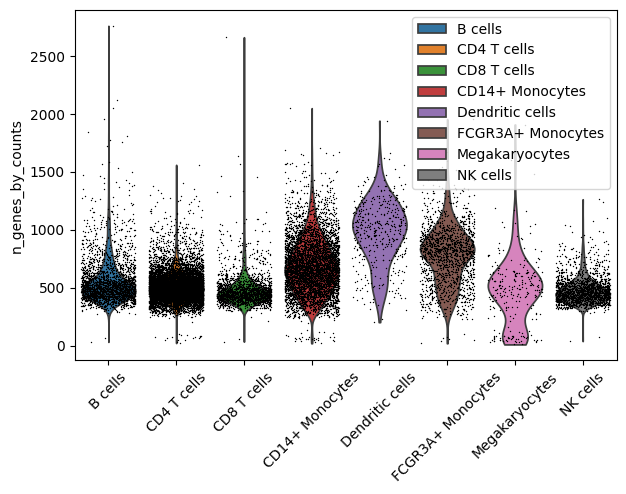

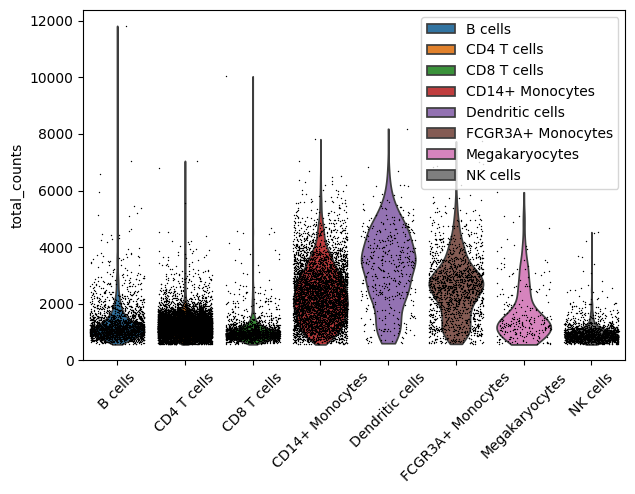

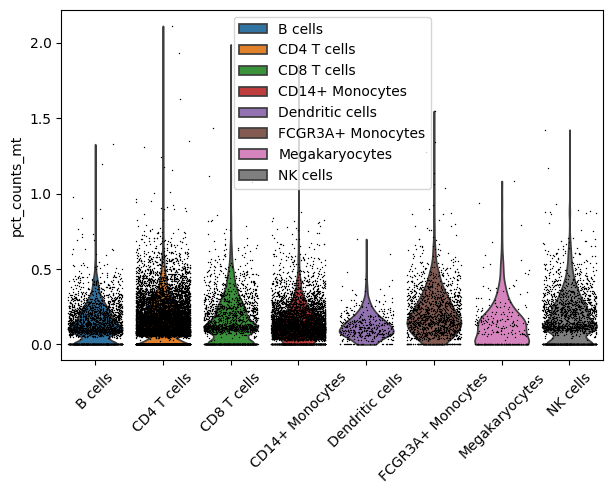

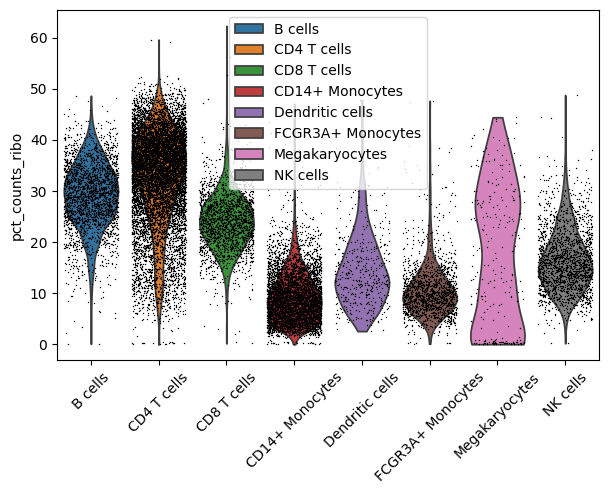

<Axes: xlabel='total_counts', ylabel='n_genes_by_counts'>

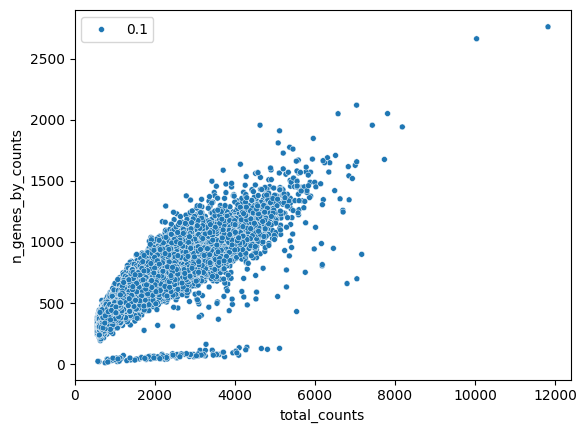

In [20]:
adata.obs['cluster'] = pd.Categorical(adata.obs['cluster'])
sc.pl.violin(adata, ['n_genes_by_counts'] #, 'total_counts','pct_counts_mt', 'pct_counts_ribo']
             ,jitter=0.4, groupby = 'cell', rotation= 45)
sc.pl.violin(adata, ['total_counts'] #,'pct_counts_mt', 'pct_counts_ribo']
             ,jitter=0.4, groupby = 'cell', rotation= 45)
sc.pl.violin(adata, ['pct_counts_mt'] #,'pct_counts_mt', 'pct_counts_ribo']
             ,jitter=0.4, groupby = 'cell', rotation= 45)
sc.pl.violin(adata, ['pct_counts_ribo'] #,'pct_counts_mt', 'pct_counts_ribo']
             ,jitter=0.4, groupby = 'cell', rotation= 45)
sns.scatterplot(data=adata.obs, x="total_counts", y="n_genes_by_counts", size = 0.1)


<Axes: xlabel='total_counts', ylabel='pct_counts_mt'>

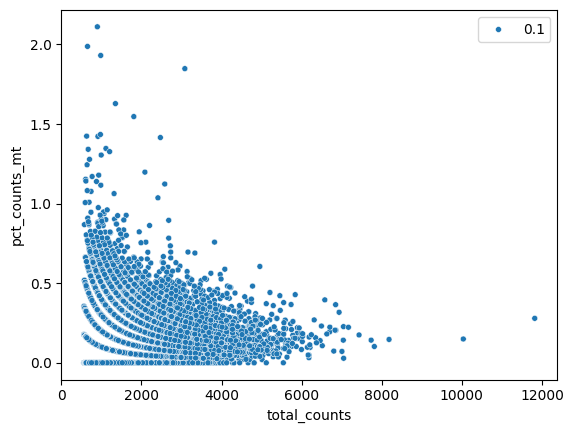

In [21]:
sns.scatterplot(data=adata.obs, x="total_counts", y="pct_counts_mt", size = 0.1)

In [22]:
adata = adata[adata.obs.n_genes_by_counts >= 200]
adata = adata[adata.obs.pct_counts_mt <= 1.0]
adata = adata[adata.obs.cell != 'Megakaryocytes']
adata = adata[:, adata.var.mt == False]
adata = adata[:, adata.var.ribo == False]
adata

View of AnnData object with n_obs × n_vars = 24249 × 35398
    obs: 'tsne1', 'tsne2', 'ind', 'stim', 'cluster', 'cell', 'multiplets', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'ensemble_id', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'cell_colors'

In [23]:
adata.obs.rename({"cell": "cell_type"}, axis=1, inplace=True)
adata.obs.rename({"stim": "condition"}, axis=1, inplace=True)
adata.obs.rename({"ind": "replicate"}, axis=1, inplace=True)
adata.obs["condition"].replace({"ctrl": "control", "stim": "stimulated"}, inplace=True)
adata.layers['counts'] = adata.X 
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

In [24]:
sc.pp.highly_variable_genes(adata, subset=True, n_top_genes = 5000)
adata

AnnData object with n_obs × n_vars = 24249 × 5000
    obs: 'tsne1', 'tsne2', 'replicate', 'condition', 'cluster', 'cell_type', 'multiplets', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'ensemble_id', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'cell_colors', 'log1p', 'hvg'
    layers: 'counts'

In [25]:
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

In [26]:
adata.obs['replicate'] = adata.obs['replicate'].astype(str)
adata

AnnData object with n_obs × n_vars = 24249 × 5000
    obs: 'tsne1', 'tsne2', 'replicate', 'condition', 'cluster', 'cell_type', 'multiplets', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'ensemble_id', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'cell_colors', 'log1p', 'hvg', 'pca', 'neighbors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

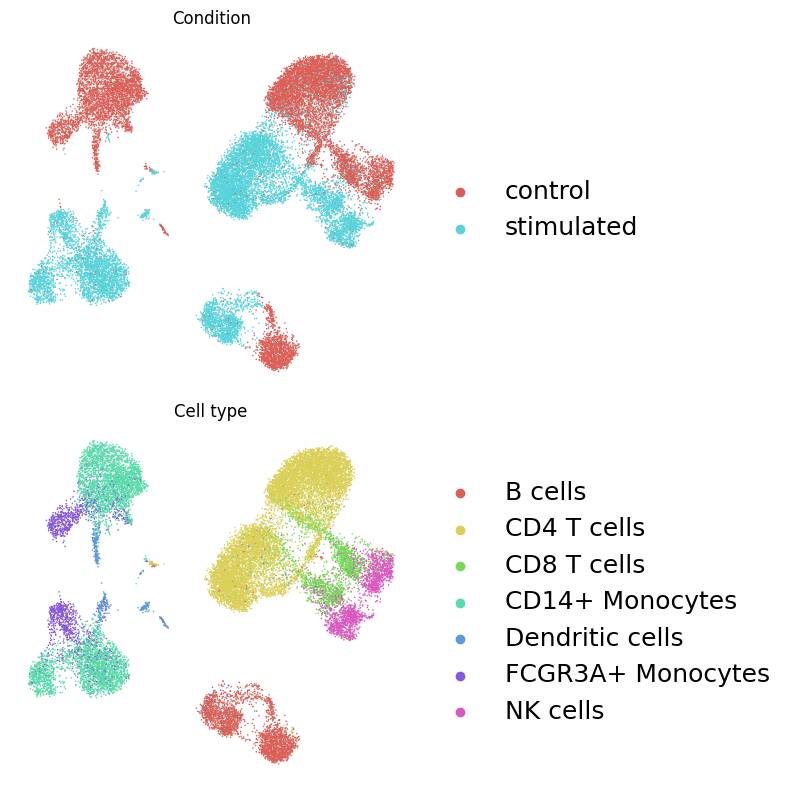

In [27]:
fig, axes = plt.subplots(nrows=2, figsize=(8, 8))  # Adjust figsize as needed
# Plot UMAP 1 in the first subplot if it's not empty
sc.pl.umap(adata=adata, color=["condition"],legend_fontsize=18,ax = axes[0],
           title = "Condition",
           show=False, palette = sns.color_palette("hls", 2),
           frameon=False)

sc.pl.umap(adata=adata, color=["cell_type"],legend_fontsize=18,ax = axes[1],
           title = "Cell type",
           show=False, palette = sns.color_palette("hls", 7),
           frameon=False)

# Adjust spacing between subplots
plt.tight_layout()
plt.savefig(save_path_results+"PBMC_UMAP.pdf")
# Show the merged plot
plt.show()

In [28]:
adata.layers['counts'].A.max()
adata.X.A.max()

6.36206463737183

In [29]:
#pd.read_csv(data_path+'GSE96583_batch1.total.tsne.df.tsv.gz', sep = "\t")
adata[adata.obs.condition == 'stimulated'].copy().obs.cell_type.value_counts()

cell_type
CD4 T cells          5087
CD14+ Monocytes      2512
B cells              1230
NK cells             1046
CD8 T cells           937
FCGR3A+ Monocytes     825
Dendritic cells       224
Name: count, dtype: int64

In [30]:
adata[adata.obs.condition == 'control'].copy().obs.cell_type.value_counts()

cell_type
CD4 T cells          5242
CD14+ Monocytes      2828
B cells              1329
CD8 T cells          1096
NK cells              933
FCGR3A+ Monocytes     753
Dendritic cells       207
Name: count, dtype: int64

In [31]:
adata.obs['cov_cond'] = adata.obs.cell_type.astype(str) + '_' + adata.obs.condition.astype(str)


In [32]:
adata.write(save_path_data+'Kang.h5ad')

In [33]:
adata

AnnData object with n_obs × n_vars = 24249 × 5000
    obs: 'tsne1', 'tsne2', 'replicate', 'condition', 'cluster', 'cell_type', 'multiplets', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'cov_cond'
    var: 'ensemble_id', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'cell_colors', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'condition_colors', 'cell_type_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [34]:
ctrl = adata[adata.obs.condition == 'control'].copy()
ctrl.obs.replicate.value_counts()
pd.crosstab(adata.obs['cell_type'],adata.obs['replicate'])

replicate,101,107,1015,1016,1039,1244,1256,1488
cell_type,,,,,,,,
B cells,239,99,798,234,64,212,420,493
CD4 T cells,663,344,1582,770,447,1926,1944,2653
CD8 T cells,178,34,312,1022,55,89,241,102
CD14+ Monocytes,449,375,1446,700,260,706,770,634
Dendritic cells,55,21,60,34,27,80,58,96
FCGR3A+ Monocytes,218,67,475,241,74,91,168,244
NK cells,174,84,371,315,42,219,494,280
